# The FIR and the recursive half-bands, measured through the C ABI

`rational`'s IIR-d notebook (`docs/IIR_PLAN.md` I11). It measures the half-band by 2 three ways, the FIR
Nyquist stage and the recursive stage in both phase variants (nonlinear, near-linear), each alone and with
the guard band filter in either form (the Chebyshev II and the linear-phase type II FIR) at the named
setting behind it, after the decimator or before the interpolator. Every number is the **shipping C++**,
run through the C ABI (`capi/tap_sr_rational_capi.h`) by the ctypes binding (`tap_sr_rational_py.py`);
`iir_measure.py` holds the measurements, shared with `guard_band_demo.ipynb` and the book.

What it measures, per profile and direction: the multiplies per output frame, the nominal and the exact
latency and the passband's delay deviation (the C ABI's getters), the response to coherent tones, and from
it the aliases a decimator leaves and the images an interpolator leaves, by where they land. The rates are
labels: 96 kHz in, 48 kHz out going down, 48 kHz in, 96 kHz out going up.

In [1]:
import pathlib, sys
import numpy as np
import matplotlib.pyplot as plt

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE))
import figure_digest  # prints a data digest per figure (A/B gates)
figure_digest.install()
import tap_sr_rational_py as rp
import iir_measure as im

print("rational", rp.version())
PROFILES = ["super_economy", "economy", "balanced", "transparent"]

rational (0, 9, 0)


## The cost and the latency

Multiplies per output frame per channel (the guard band filter's at the low rate, over 2 going up), the
nominal latency in output frames (the group delay at DC, or the near-linear variant's exact delay path),
the exact latency where every part of the configuration has one (the FIR stage and the linear form), and
the largest stray of the passband's group delay from the nominal, sampled on 512 points to the passband
edge from the C ABI's group delay getter.

In [2]:
def deviation(parts, direction, p):
    f = np.linspace(0.0, p / (1.0 if direction == "down" else 2.0), 513)
    g = np.array([im.group_delay(parts, fi, direction) for fi in f])
    return float(np.max(np.abs(g - im.nominal_latency(parts, direction))))

rows = {}
for prof in PROFILES:
    a, p = im.PROFILES[prof]
    for direction in ("down", "up"):
        for name, parts in im.configurations(direction, prof).items():
            exact = im.exact_latency(parts, direction)
            rows[(prof, direction, name)] = (im.macs_per_output(parts, direction), im.nominal_latency(parts, direction),
                                             exact, deviation(parts, direction, p))
for prof in PROFILES:
    print(f"\n{prof}")
    print(f"  {'by 2':4s} {'configuration':30s} {'MACs':>6s} {'nominal':>9s} {'exact':>7s} {'deviation':>10s}")
    for direction in ("down", "up"):
        for name in im.configurations(direction, prof):
            macs, nom, exact, dev = rows[(prof, direction, name)]
            ex = "—" if exact is None else str(exact)
            print(f"  {direction:4s} {name:30s} {macs:6.1f} {nom:9.4f} {ex:>7s} {dev:10.4f}")


super_economy
  by 2 configuration                    MACs   nominal   exact  deviation
  down FIR alone                        17.0    7.5000    15/2     0.0000
  down FIR + Chebyshev II               37.0    8.2461       —     3.3716
  down FIR + linear form                55.0   26.0000      26     0.0000
  down IIR nonlinear alone               4.0    1.2666       —     0.8406
  down IIR nonlinear + Chebyshev II     19.0    1.7558       —     2.6843
  down IIR nonlinear + linear form      34.0   15.7666       —     0.8406
  down IIR near-linear alone             5.0    5.0000       —     0.0078
  down IIR near-linear + Chebyshev II   25.0    5.7461       —     3.3794
  down IIR near-linear + linear form    43.0   23.5000       —     0.0078
  up   FIR alone                         8.5   15.0000      15     0.0000
  up   FIR + Chebyshev II               18.5   16.4921       —     6.7431
  up   FIR + linear form                27.5   52.0000      52     0.0000
  up   IIR nonlinear al

## The response, the aliases and the images

Each decimator gets coherent tones from DC to the input Nyquist: the level at each tone's output bin over
its input level is the passband response below the low Nyquist and the **alias** above it, landing at the
low rate minus the tone. Each interpolator gets low-rate tones: the level at the tone and at its **image**,
the low rate minus it. The figure is `economy`; the shaded bands are where an alias lands (or an image
comes from) in the guard band, between the passband edge and the guard band filter's stop edge.

[ figure ] digest e3a8cb5dc9c6c33c (24 arrays)


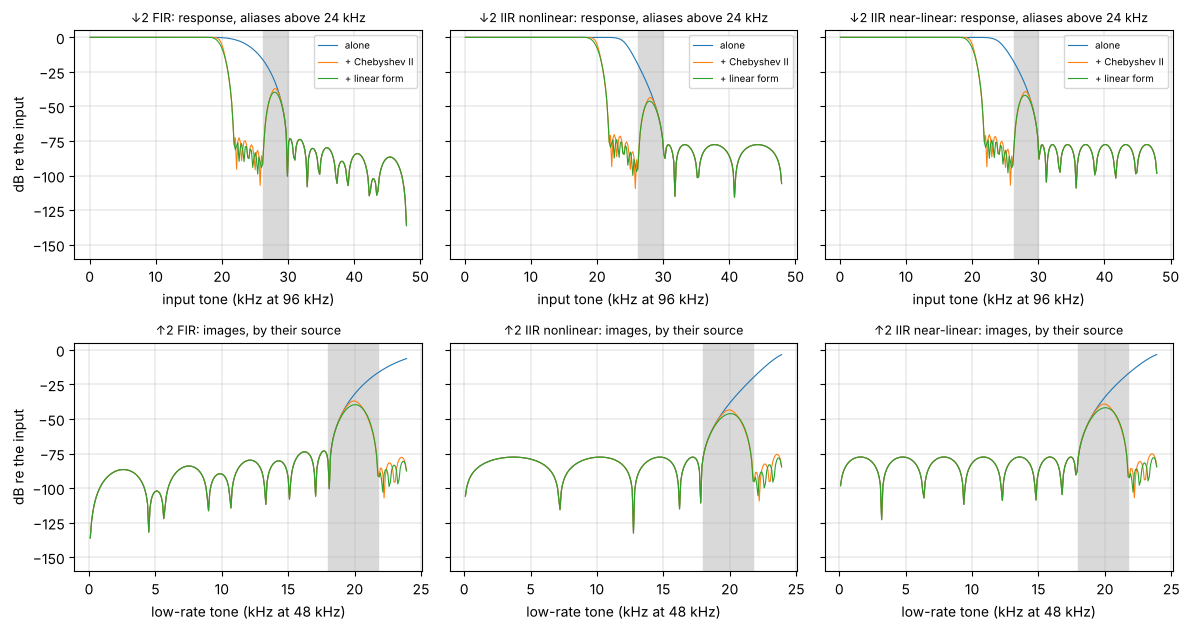

In [3]:
M_DOWN = np.arange(8, im.N_FFT, 16)           # tones at m / (2 N_FFT) cycles per input frame
M_UP = np.arange(8, im.N_FFT // 2, 8)          # low-rate tones at m / N_FFT
F_DOWN = M_DOWN / (2.0 * im.N_FFT) * im.RATE_HIGH
F_UP = M_UP / im.N_FFT * im.RATE_LOW

responses = {}
for prof in PROFILES:
    for name, parts in im.configurations("down", prof).items():
        responses[(prof, "down", name)] = im.decimator_response(parts, M_DOWN)
    for name, parts in im.configurations("up", prof).items():
        responses[(prof, "up", name)] = im.interpolator_response(parts, M_UP)

prof = "economy"
a, p = im.PROFILES[prof]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharey=True)
for col, variant in enumerate(im.VARIANTS):
    edge = im.stop_edge(prof, im.VARIANTS[variant]) * im.RATE_LOW
    for name in (f"{variant} alone", f"{variant} + Chebyshev II", f"{variant} + linear form"):
        axes[0, col].plot(F_DOWN / 1000, responses[(prof, "down", name)], lw=0.8, label=name.replace(variant + " ", ""))
        _, img = responses[(prof, "up", name)]
        axes[1, col].plot(F_UP / 1000, img, lw=0.8, label=name.replace(variant + " ", ""))
    axes[0, col].axvspan((im.RATE_LOW - edge) / 1000, (1 - p) * im.RATE_LOW / 1000, color="0.85")
    axes[1, col].axvspan(p * 48, edge / 1000, color="0.85")
    axes[0, col].set_title(f"↓2 {variant}: response, aliases above 24 kHz", fontsize=9)
    axes[1, col].set_title(f"↑2 {variant}: images, by their source", fontsize=9)
    axes[0, col].set_xlabel("input tone (kHz at 96 kHz)")
    axes[1, col].set_xlabel("low-rate tone (kHz at 48 kHz)")
    axes[0, col].legend(fontsize=7)
for ax in axes.ravel():
    ax.set_ylim(-160, 5)
    ax.grid(True, lw=0.3)
axes[0, 0].set_ylabel("dB re the input")
axes[1, 0].set_ylabel("dB re the input")
plt.tight_layout()
plt.show()

The worst alias of every decimator, and the worst image of every interpolator, by where it lands (an alias)
or where its source sits (an image): the passband (to the profile's edge, where every half-band holds the
profile's A), the guard band (the edge to the guard band filter's stop edge for the setting behind that
half-band) and above it (to the low Nyquist); and the passband ripple, peak to peak.

In [4]:
def regions(f_out_hz, levels, prof, kind):
    a, p = im.PROFILES[prof]
    edge = im.stop_edge(prof, kind) * im.RATE_LOW
    pb = levels[f_out_hz <= p * im.RATE_LOW]
    gb = levels[(f_out_hz > p * im.RATE_LOW) & (f_out_hz < edge)]
    ab = levels[(f_out_hz >= edge) & (f_out_hz < im.RATE_LOW / 2)]
    return [float(np.max(v)) if len(v) else float("nan") for v in (pb, gb, ab)]

summary = {}
for prof in PROFILES:
    a, p = im.PROFILES[prof]
    print(f"\n{prof} (A = {a:.0f} dB): worst level in dB re the input")
    print(f"  {'by 2':4s} {'configuration':30s} {'ripple':>7s} {'passband':>9s} {'guard band':>11s} {'above':>7s}")
    for direction in ("down", "up"):
        for name in im.configurations(direction, prof):
            kind = im.VARIANTS[name.split(" +")[0].replace(" alone", "")]
            if direction == "down":
                lv = responses[(prof, "down", name)]
                passband = lv[F_DOWN <= p * im.RATE_LOW]
                above = F_DOWN > im.RATE_LOW / 2
                worst = regions(im.RATE_LOW - F_DOWN[above], lv[above], prof, kind)
            else:
                passband_lv, img = responses[(prof, "up", name)]
                passband = passband_lv[F_UP <= p * im.RATE_LOW]
                worst = regions(F_UP, img, prof, kind)
            ripple = float(np.max(passband) - np.min(passband))
            summary[(prof, direction, name)] = (ripple, *worst)
            print(f"  {direction:4s} {name:30s} {ripple:7.4f} {worst[0]:9.1f} {worst[1]:11.1f} {worst[2]:7.1f}")


super_economy (A = 70 dB): worst level in dB re the input
  by 2 configuration                   ripple  passband  guard band   above
  down FIR alone                       0.0036     -72.4       -18.9    -6.3
  down FIR + Chebyshev II              0.0062     -72.4       -40.9   -77.9
  down FIR + linear form               0.0105     -72.4       -42.7   -78.2
  down IIR nonlinear alone             0.0000     -90.0       -13.6    -3.4
  down IIR nonlinear + Chebyshev II    0.0079     -90.0       -40.1   -75.2
  down IIR nonlinear + linear form     0.0085     -90.0       -44.4   -76.5
  down IIR near-linear alone           0.0000     -75.5       -18.7    -3.3
  down IIR near-linear + Chebyshev II  0.0070     -75.5       -39.6   -75.2
  down IIR near-linear + linear form   0.0090     -75.5       -41.7   -75.4
  up   FIR alone                       0.0037     -72.4       -18.4    -6.3
  up   FIR + Chebyshev II              0.0077     -72.4       -40.9   -77.9
  up   FIR + linear form     

## The group delay over the passband

At `economy`, in output frames at 48 kHz going down and at 96 kHz going up, from the C ABI's getters: the
FIR stage and the linear form are flat (an exact latency); the recursive variants and the Chebyshev II are
not, the near-linear variant within a hundredth of a frame of its delay path.

[ figure ] digest 2412eb41337576ea (18 arrays)


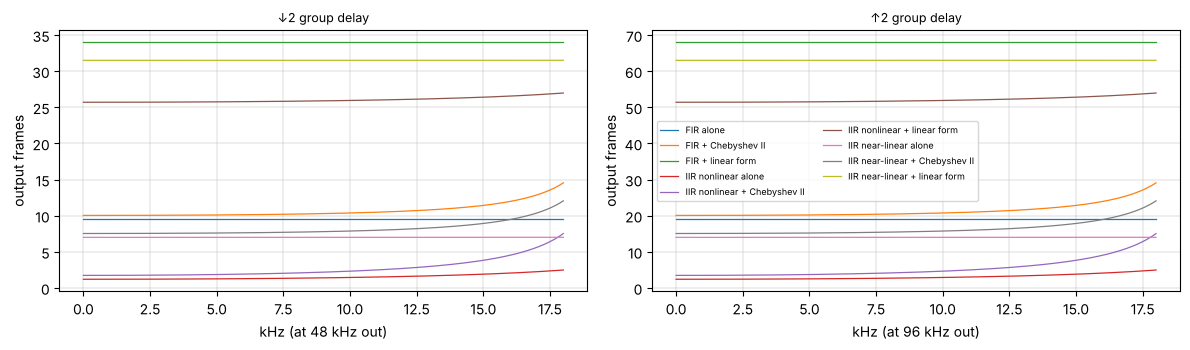

In [5]:
prof = "economy"
a, p = im.PROFILES[prof]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, direction in zip(axes, ("down", "up")):
    rate = im.RATE_LOW if direction == "down" else im.RATE_HIGH
    f = np.linspace(0.0, p / (1.0 if direction == "down" else 2.0), 400)
    for name, parts in im.configurations(direction, prof).items():
        ax.plot(f * rate / 1000, [im.group_delay(parts, fi, direction) for fi in f], lw=0.9, label=name)
    ax.set_xlabel(f"kHz (at {rate / 1000:.0f} kHz out)")
    ax.set_ylabel("output frames")
    ax.set_title(f"↓2 group delay" if direction == "down" else "↑2 group delay", fontsize=9)
    ax.grid(True, lw=0.3)
axes[1].legend(fontsize=6.5, ncol=2)
plt.tight_layout()
plt.show()

## Reading it

- Every half-band holds the profile's A where an alias lands in the passband (or an image comes from it),
  alone or with either form: −71 to −90 dB at the 70 dB profiles, −120 to −126 dB at `transparent`.
- Alone, every half-band leaves the guard band and the band above it nearly unattenuated: −3.3 to −4.1 dB
  above the stop edge for the recursive variants (power complementary, −3 dB at the crossover) and −6.3 to
  −6.6 dB for the FIR stage. With either form the worst alias in the guard band is at or below −A/2 behind
  the half-band its setting is named for (−37 to −46 dB at the 70 dB profiles, −60.6 to −64.8 dB at
  `transparent`), and above the stop edge it is past A (−75 to −81 dB, −125 to −130 dB).
- The recursive half-band costs a fifth of the FIR one or less (4 multiplies per decimated output against 21
  at `economy`); the Chebyshev II costs 20 there, about the FIR half-band, and the linear form 50. The linear
  form keeps an exact latency behind the FIR stage and an exact delay path behind the near-linear variant;
  the Chebyshev II makes any chain's latency nominal, and adds most of its delay at the passband edge.